# Positive cells in the junction band

**The question.** Each assembloid is two organoids fused together. A **junction line** is drawn where they meet, and a **band** 300 µm wide is drawn on one side of it, reaching into one organoid. How many cells in that band are positive for a channel — mainly **AF488**, the label whose cells migrate — and does that differ between genotypes (WT3 against GD1)?

**How.** Every cell of each annotated section was segmented once (Cellpose, on the nuclear channel AF405) and its brightness measured in each channel over the nucleus grown by 3 µm (`count_cells.py`). The shared module `count_common.py` places each cell: whether it lies in the band, its distance from the junction line and its distance from the tissue edge. Nothing is segmented here; this notebook only counts.

**The band.** `first` is the first annotator's hand-drawn band, the main one. `second` (Quillan's) is shown as a check where both were drawn: if the answer changes with who drew the band, it is not to be trusted.

**Four rules for "positive"**, each a threshold on the cell's brightness:

| short name | rule | what it compares the cell with |
|---|---|---|
| band +3 SD | above median + 3 SD of the band's cells (what the junction analysis does now) | the other cells of the same band |
| band +7 SD, filtered | the same at 7 SD, after subtracting the local median (45 µm), which removes slow haze | the band's cells, haze removed |
| negative 99.9th pct | above the 99.9th percentile of a **negative control**: cells deep (> 300 µm) in the organoid where the channel is not at home, away from the tissue edge | cells that should not carry the label |
| ring contrast, no autofl. | the cell is brighter than its own surrounding ring by more than 99 % of the negative control cells are, and not as bright (relative to its ring) in the other channel — a cell bright in every channel is autofluorescence | its own local background, and the other channel |

**The numbers.** For each sample: the cells in the band, how many are positive, the **% positive**, and the **positives per mm of junction** (positives divided by the length of the line in mm), so that a long junction does not count for more. The genotype tests use Mann-Whitney U on samples and again on slide means (sections of one slide may come from one assembloid, so the slide is the safer unit).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import count_common as C

warnings.filterwarnings("ignore", category=RuntimeWarning)       # medians of empty groups, small-n tests
pd.set_option("display.width", 200)

cells, meta = C.load_all()
LABEL = C.label_channel(meta)
CHANNELS = list(meta["channels"].iloc[0])
LINES = [b for b in ("first", "second") if meta["bands"].apply(lambda x: b in x).any()]

# The four positivity rules compared, with short names for tables and figures.
RULE_NAMES = {
    "band median + 3 SD (current)": "band +3 SD",
    "band median + 7 SD, median filter": "band +7 SD, filtered",
    "negative control 99.9th pct": "negative 99.9th pct",
    "ring contrast > negative 99th pct, no autofluorescence": "ring contrast, no autofl.",
}
RULES = {ch: {RULE_NAMES[k]: f for k, f in C.rules(CHANNELS, ch).items() if k in RULE_NAMES} for ch in CHANNELS}
SHORT_RULES = list(RULE_NAMES.values())
GENOTYPE_COLOURS = {"WT3": "tab:blue", "GD1": "tab:orange", "WT2": "tab:green"}



def tidy(table, digits=2):
    """Round the numeric columns of a table that mixes numbers and text (compare_groups)."""
    table = table.copy()
    for c in table.columns:
        values = pd.to_numeric(table[c], errors="coerce")
        if values.notna().sum() == table[c].notna().sum():
            table[c] = values.round(digits)
    return table


print(f"label channel: {LABEL}; channels: {CHANNELS}; lines: {LINES}")
design = meta[["Genotype", "Experiment", "slide"]].copy()
design.index = [C.short(n) for n in design.index]
print("samples per genotype and experiment:")
display(pd.crosstab(design["Genotype"], design["Experiment"], margins=True))

30 of 30 annotated samples measured, 919,868 cells; bands: first 30, second 27, automatic 26
label channel: AF488; channels: ['AF555', 'AF488']; lines: ['first', 'second']
samples per genotype and experiment:


Experiment,8,9,10,All
Genotype,,,,
GD1,5,6,8,19
WT3,2,3,6,11
All,7,9,14,30


## 1. Counting

Each rule is applied to every cell of the section, then the cells in the band are counted. Per sample, band, channel and rule: cells in the band, positives, % positive and positives per mm of junction.

In [2]:
calls = {}      # (sample, band, channel, rule) -> positive per cell (whole section)
rows = []
for name, df in cells.items():
    for band in LINES:
        if f"in {band}" not in df:
            continue
        inside = C.region(df, "band", band, LABEL)
        length_mm = meta.loc[name, "lengths (um)"][band] / 1000
        for ch in CHANNELS:
            for rule, f in RULES[ch].items():
                pos = np.asarray(f(df, band), bool)
                calls[(name, band, ch, rule)] = pos
                n_pos = int((pos & inside).sum())
                rows.append({"name": name, "sample": C.short(name), "band": band, "channel": ch, "rule": rule,
                             "cells in band": int(inside.sum()), "positives": n_pos,
                             "% positive": 100 * n_pos / inside.sum() if inside.sum() else np.nan,
                             "per mm": n_pos / length_mm if length_mm else np.nan,
                             "junction (mm)": length_mm,
                             **meta.loc[name, ["Genotype", "Experiment", "slide"]].to_dict()})
counts = pd.DataFrame(rows)
print(f"{counts['sample'].nunique()} samples, {len(counts)} counts")

30 samples, 456 counts


### Per sample: AF488 in the first annotator's band

One row per sample. For each rule: the number of positive cells, the % of the band's cells that are positive, and the positives per mm of junction. Read across a row to see how much the answer depends on the rule; read down a column to see how samples differ.

In [3]:
main = counts[(counts.band == "first") & (counts.channel == LABEL)]
table = main.pivot_table(index=["Genotype", "sample"], columns="rule",
                         values=["positives", "% positive", "per mm"], sort=False)
table = table.reorder_levels([1, 0], axis=1)[[(r, v) for r in SHORT_RULES for v in ("positives", "% positive", "per mm")]]
cells_in_band = main.groupby(["Genotype", "sample"])["cells in band"].first()
table.insert(0, ("", "cells in band"), cells_in_band)
table.insert(1, ("", "junction (mm)"), main.groupby(["Genotype", "sample"])["junction (mm)"].first())
table.sort_index().round(1)

rule                                             band +3 SD                   band +7 SD, filtered                   negative 99.9th pct                   ring contrast, no autofl.                  
                     cells in band junction (mm)  positives % positive per mm            positives % positive per mm           positives % positive per mm                 positives % positive per mm
Genotype sample                                                                                                                                                                                       
GD1      039-038_s5           5558           1.1       64.0        1.2   60.8                 36.0        0.6   34.2                24.0        0.4   22.8                      49.0        0.9   46.5
         041-040_s1           2040           0.6      261.0       12.8  407.1                  7.0        0.3   10.9               110.0        5.4  171.6                      12.0        0.6   18.7
         041-040_s16          3712           1.1      155.0        4.2  144.3                  0.0        0.0    0.0               131.0        3.5  122.0                      19.0        0.5   17.7
         041-040_s26          4324           1.2       82.0        1.9   66.9                  7.0        0.2    5.7                13.0        0.3   10.6                      30.0        0.7   24.5
         044-043_s19           773           0.7        0.0        0.0    0.0                  0.0        0.0    0.0                 1.0        0.1    1.5                       7.0        0.9   10.5
         045-044_s15         10421           1.4       76.0        0.7   55.3                  9.0        0.1    6.6               118.0        1.1   85.9                      64.0        0.6   46.6
         045-044_s16           454           0.4        0.0        0.0    0.0                  1.0        0.2    2.5                 0.0        0.0    0.0                       5.0        1.1   12.4
         045-044_s4           1598           0.4       16.0        1.0   41.3                 13.0        0.8   33.6               263.0       16.5  678.9                      11.0        0.7   28.4
         048-047_s6           8483           1.5      137.0        1.6   94.5                 34.0        0.4   23.4                38.0        0.4   26.2                      88.0        1.0   60.7
         050-049_s5           3135           0.7       15.0        0.5   21.9                  3.0        0.1    4.4                11.0        0.4   16.1                      21.0        0.7   30.7
         051-050_s12          2808           1.0       86.0        3.1   88.2                 53.0        1.9   54.4                45.0        1.6   46.2                      19.0        0.7   19.5
         052-051_s14          8936           1.2      529.0        5.9  452.5                  7.0        0.1    6.0                 0.0        0.0    0.0                      14.0        0.2   12.0
         052-051_s18          4858           0.8       14.0        0.3   18.3                 17.0        0.3   22.3               171.0        3.5  224.1                      89.0        1.8  116.6
         052-051_s23          2144           0.4        0.0        0.0    0.0                  0.0        0.0    0.0                 3.0        0.1    8.0                      40.0        1.9  106.3
         053-052_s5           4861           1.3      305.0        6.3  235.5                 13.0        0.3   10.0                83.0        1.7   64.1                      73.0        1.5   56.4
         054-053_s7           5563           1.2      476.0        8.6  400.5                  7.0        0.1    5.9                61.0        1.1   51.3                      18.0        0.3   15.1
         055-054_s15          7968           1.2       62.0        0.8   51.7                  8.0        0.1    6.7                13.0        0.2   10.9                      76.0        1.0   63.4
         055-054_s23

### Summary, both channels and both bands

Median over samples. **Caveat for AF555:** the band usually reaches into the organoid where AF555 is at home (see `counts_crossed`), so most AF555-positive cells in the band are that organoid's own cells, not migrants. Its % positive in the band says how bright that organoid is, not how many cells crossed. For AF488 the band usually reaches into the other organoid, so its positives in the band are candidate migrants.

In [4]:
summary = (counts.groupby(["channel", "band", "rule"], sort=False)
           .agg(samples=("sample", "nunique"), **{"cells in band": ("cells in band", "median"),
                "positives": ("positives", "median"), "% positive": ("% positive", "median"),
                "per mm": ("per mm", "median")}))
summary.reindex([LABEL] + [c for c in CHANNELS if c != LABEL], level="channel").round(1)

samples  cells in band  positives  % positive  per mm
channel band   rule                                                                            
AF488   first  band +3 SD                      30         5209.5       98.5         1.5    85.1
               band +7 SD, filtered            30         5209.5       11.0         0.3    11.8
               negative 99.9th pct             30         5209.5       35.0         0.4    25.5
               ring contrast, no autofl.       30         5209.5       58.0         1.0    53.3
        second band +3 SD                      27         5785.0      143.0         1.6    92.4
               band +7 SD, filtered            27         5785.0       11.0         0.3    13.4
               negative 99.9th pct             27         5785.0       45.0         1.0    35.0
               ring contrast, no autofl.       27         5785.0       69.0         1.2    49.8
AF555   first  band +3 SD                      30         5209.5      224.5         5.8   318.8
               band +7 SD, filtered            30         5209.5       66.5         2.1    95.3
               negative 99.9th pct             30         5209.5      244.0         5.1   202.6
               ring contrast, no autofl.       30         5209.5      167.0         3.6   151.8
        second band +3 SD                      27         5785.0      288.0         6.3   267.8
               band +7 SD, filtered            27         5785.0       83.0         2.2   105.2
               negative 99.9th pct             27         5785.0      310.0         9.0   225.9
               ring contrast, no autofl.       27         5785.0      241.0         3.8   193.8

### Check: first against second band

Where both annotators drew a band, the same counts from each. **CCC** (Lin's concordance) is 1 when the two give identical numbers per sample; **|second − first| / mean** is the typical relative difference (0.1 = the two differ by 10 %). Shown for % positive and positives per mm. With fewer than 3 samples CCC is not computed.

In [5]:
def agreement(frame, value):
    w = frame.pivot_table(index=["sample", "channel", "rule"], columns="band", values=value).dropna()
    out = []
    for (ch, rule), g in w.groupby(level=["channel", "rule"], sort=False):
        a, b = g["first"], g["second"]
        rel = ((b - a).abs() / ((a + b) / 2)).replace([np.inf, -np.inf], np.nan)
        out.append({"channel": ch, "rule": rule, "value": value, "n": len(g), "first (median)": a.median(),
                    "second (median)": b.median(), "|second − first| / mean (median)": rel.median(),
                    "CCC": C.ccc(a, b)})
    return pd.DataFrame(out)


if "second" in LINES:
    display(pd.concat([agreement(counts, "% positive"), agreement(counts, "per mm")])
            .set_index(["channel", "value", "rule"]).sort_index(level=[0, 1], sort_remaining=False).round(2))
else:
    print("no second band drawn on the measured samples")

n  first (median)  second (median)  |second − first| / mean (median)   CCC
channel value      rule                                                                                                  
AF488   % positive band +3 SD                 27            1.61             1.64                              0.06  0.97
                   band +7 SD, filtered       27            0.34             0.28                              0.10  0.63
                   negative 99.9th pct        27            0.44             1.04                              0.18  0.98
                   ring contrast, no autofl.  27            1.05             1.25                              0.13  0.75
        per mm     band +3 SD                 27           93.98            92.37                              0.11  0.96
                   band +7 SD, filtered       27           12.63            13.44                              0.18  0.95
                   negative 99.9th pct        27           26.20            35.00                              0.24  0.91
                   ring contrast, no autofl.  27           56.37            49.81                              0.13  0.95
AF555   % positive band +3 SD                 27            5.90             6.29                              0.07  0.96
                   band +7 SD, filtered       27            2.24             2.24                              0.07  0.95
                   negative 99.9th pct        27           10.25             8.97                              0.22  0.86
                   ring contrast, no autofl.  27            3.81             3.83                              0.08  0.95
        per mm     band +3 SD                 27          335.34           267.81                              0.10  0.96
                   band +7 SD, filtered       27          101.67           105.19                              0.08  0.96
                   negative 99.9th pct        27          415.78           225.86                              0.25  0.88
                   ring contrast, no autofl.  27          199.17           193.80                              0.09  0.96

## 2. Where in the band are the positive cells?

The band's cells are split by their **distance from the junction line** (0–50, 50–100, 100–200, 200–300 µm into the band) and, separately, by their **distance to the tissue edge** (≤ 20, 20–100, > 100 µm). In each bin, the % of cells that are positive; then the median over samples. A few band cells lie just behind the line or a little beyond 300 µm (where the band's ends are cut obliquely); they go in the nearest end bin.

**How to read it.** If migrating cells enter from the line, % positive should fall with distance from the line. If they travel along the surface of the tissue, % positive should be highest near the edge. The second table shows how the band's cells are spread over the bins (median share), so a bin with very few cells is not over-read.

In [6]:
LINE_BINS = ([-np.inf, 50, 100, 200, np.inf], ["0–50", "50–100", "100–200", "200–300"])
EDGE_BINS = ([-np.inf, 20, 100, np.inf], ["≤ 20", "20–100", "> 100"])

bin_rows = []
for name, df in cells.items():
    inside = C.region(df, "band", "first", LABEL)
    if not inside.any():
        continue
    by = {"from the line (µm)": pd.cut(df.loc[inside, "from first (um)"], LINE_BINS[0], labels=LINE_BINS[1]),
          "from the edge (µm)": pd.cut(df.loc[inside, "edge (um)"], EDGE_BINS[0], labels=EDGE_BINS[1])}
    for rule in SHORT_RULES:
        pos = calls[(name, "first", LABEL, rule)][inside]
        for axis, bins in by.items():
            g = pd.DataFrame({"bin": bins.to_numpy(), "pos": pos}).groupby("bin", observed=False)["pos"]
            for b, n, k in zip(g.size().index, g.size(), g.sum()):
                bin_rows.append({"sample": C.short(name), "Genotype": meta.loc[name, "Genotype"], "rule": rule,
                                 "by": axis, "bin": b, "cells": n, "share of band (%)": 100 * n / inside.sum(),
                                 "% positive": 100 * k / n if n else np.nan})
bins_df = pd.DataFrame(bin_rows)
order = {"from the line (µm)": LINE_BINS[1], "from the edge (µm)": EDGE_BINS[1]}
for axis in order:
    sub = bins_df[bins_df.by == axis]
    pct = sub.pivot_table(index="rule", columns="bin", values="% positive", aggfunc="median", observed=False)
    print(f"{LABEL} % positive by distance {axis}, first band — median over samples:")
    display(pct.reindex(index=SHORT_RULES, columns=order[axis]).round(2))
    share = sub[sub.rule == SHORT_RULES[0]].groupby("bin", observed=False)["share of band (%)"].median()
    print("median share of the band's cells in each bin (%):", share.reindex(order[axis]).round(1).to_dict())

AF488 % positive by distance from the line (µm), first band — median over samples:


bin,0–50,50–100,100–200,200–300
rule,,,,
band +3 SD,1.38,1.94,1.17,0.74
"band +7 SD, filtered",0.49,0.29,0.18,0.07
negative 99.9th pct,0.80,0.31,0.39,0.23
"ring contrast, no autofl.",1.95,1.20,0.81,0.65


median share of the band's cells in each bin (%): {'0–50': 13.2, '50–100': 16.4, '100–200': 34.5, '200–300': 35.9}
AF488 % positive by distance from the edge (µm), first band — median over samples:


bin,≤ 20,20–100,> 100
rule,,,
band +3 SD,0.31,0.72,1.57
"band +7 SD, filtered",0.48,0.31,0.25
negative 99.9th pct,0.00,0.35,0.58
"ring contrast, no autofl.",3.55,1.02,0.79


median share of the band's cells in each bin (%): {'≤ 20': 3.9, '20–100': 17.9, '> 100': 77.0}


**Figure.** % positive (AF488, first band) in each bin: one line per rule, the median over samples; faint lines are the individual samples for the current rule (band +3 SD). Log scale (symlog: zero is drawn at the bottom), because the rules differ several-fold in how many cells they call.

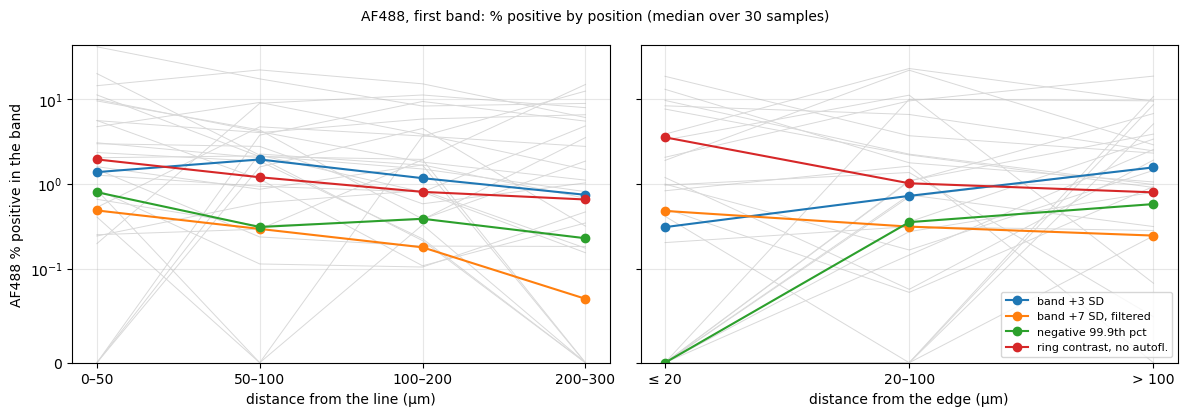

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, axis in zip(axes, order):
    sub = bins_df[bins_df.by == axis]
    x = np.arange(len(order[axis]))
    for s, g in sub[sub.rule == SHORT_RULES[0]].groupby("sample"):
        ax.plot(x, g.set_index("bin")["% positive"].reindex(order[axis]), color="0.85", lw=0.7, zorder=1)
    for rule in SHORT_RULES:
        m = sub[sub.rule == rule].groupby("bin", observed=False)["% positive"].median().reindex(order[axis])
        ax.plot(x, m, marker="o", label=rule, zorder=2)
    ax.set_xticks(x, order[axis]); ax.set_xlabel(f"distance {axis}")
    ax.set_yscale("symlog", linthresh=0.1); ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
axes[0].set_ylabel(f"{LABEL} % positive in the band"); axes[1].legend(fontsize=8)
fig.suptitle(f"{LABEL}, first band: % positive by position (median over {bins_df['sample'].nunique()} samples)", fontsize=10)
plt.tight_layout()

## 3. Genotype

Per sample, AF488 in the first band: % positive and positives per mm, under each rule. `compare_groups` gives the median per genotype, their ratio, the number of samples (or slides) per group and the Mann-Whitney p (two-sided). First on samples, then on slide means. With a handful of samples per group only a large difference can reach p < 0.05, and four rules are tested, so a single p just under 0.05 is weak evidence.

In [8]:
per_sample = main.pivot_table(index=["name"], columns="rule", values=["% positive", "per mm"])
per_sample.columns = [f"{v} · {r}" for v, r in per_sample.columns]
per_sample = per_sample.join(meta[["Genotype", "Experiment", "slide"]])
columns = [f"{v} · {r}" for v in ("% positive", "per mm") for r in SHORT_RULES]
print(f"genotypes: {per_sample['Genotype'].value_counts().to_dict()}; slides: "
      f"{per_sample.groupby('Genotype')['slide'].nunique().to_dict()}")
print("On samples:")
display(tidy(C.compare_groups(per_sample, columns, unit="sample"), 3))
print("On slide means:")
display(tidy(C.compare_groups(per_sample, columns, unit="slide"), 3))

genotypes: {'GD1': 19, 'WT3': 11}; slides: {'GD1': 11, 'WT3': 8}
On samples:


,GD1 median,WT3 median,n,WT3 / GD1,test,p
% positive · band +3 SD,1.615,1.433,19 vs 11,0.887,Mann-Whitney,0.636
"% positive · band +7 SD, filtered",0.126,0.593,19 vs 11,4.713,Mann-Whitney,0.002
% positive · negative 99.9th pct,0.439,0.424,19 vs 11,0.966,Mann-Whitney,0.763
"% positive · ring contrast, no autofl.",0.694,2.118,19 vs 11,3.053,Mann-Whitney,0.001
per mm · band +3 SD,66.944,93.980,19 vs 11,1.404,Mann-Whitney,0.547
"per mm · band +7 SD, filtered",5.987,24.095,19 vs 11,4.024,Mann-Whitney,0.001
per mm · negative 99.9th pct,22.982,27.820,19 vs 11,1.211,Mann-Whitney,0.576
"per mm · ring contrast, no autofl.",28.396,91.370,19 vs 11,3.218,Mann-Whitney,0.003


On slide means:


,GD1 median,WT3 median,n,WT3 / GD1,test,p
% positive · band +3 SD,2.069,2.226,11 vs 8,1.075,Mann-Whitney,0.778
"% positive · band +7 SD, filtered",0.168,0.580,11 vs 8,3.447,Mann-Whitney,0.016
% positive · negative 99.9th pct,1.097,0.536,11 vs 8,0.489,Mann-Whitney,0.968
"% positive · ring contrast, no autofl.",0.882,1.845,11 vs 8,2.093,Mann-Whitney,0.004
per mm · band +3 SD,94.474,135.851,11 vs 8,1.438,Mann-Whitney,0.717
"per mm · band +7 SD, filtered",9.422,25.042,11 vs 8,2.658,Mann-Whitney,0.020
per mm · negative 99.9th pct,46.166,22.144,11 vs 8,0.480,Mann-Whitney,0.657
"per mm · ring contrast, no autofl.",30.696,82.183,11 vs 8,2.677,Mann-Whitney,0.009


**Figure.** Each dot is a sample, the black bar the genotype's median. Top row % positive, bottom row positives per mm of junction; one column per rule. Dots are marked by experiment (batch), so a genotype difference carried by one batch shows up as one marker standing apart.

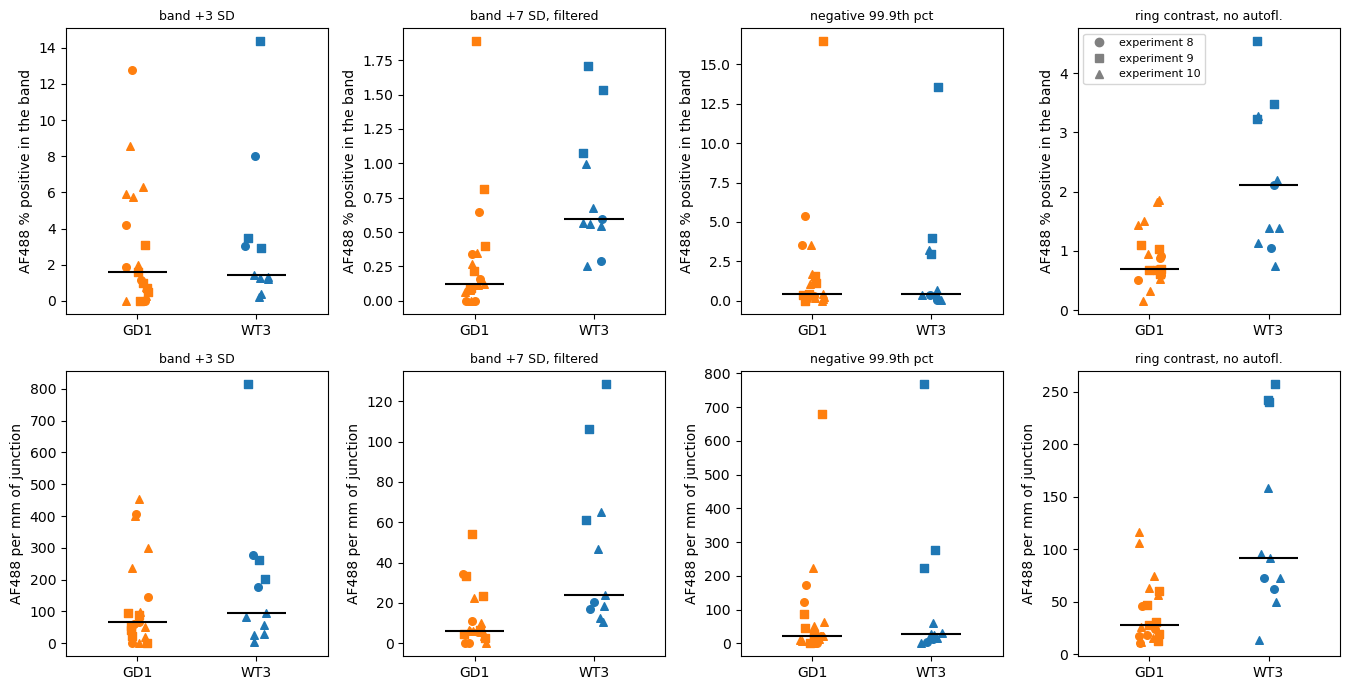

In [9]:
genotypes = sorted(per_sample["Genotype"].unique())
markers = dict(zip(sorted(per_sample["Experiment"].unique()), "os^Dv<>"))
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, len(SHORT_RULES), figsize=(3.4 * len(SHORT_RULES), 7))
for row, value in enumerate(("% positive", "per mm")):
    for ax, rule in zip(axes[row], SHORT_RULES):
        c = f"{value} · {rule}"
        for x, g in enumerate(genotypes):
            sub = per_sample[per_sample["Genotype"] == g]
            for e, s in sub.groupby("Experiment"):
                ax.scatter(x + rng.uniform(-0.1, 0.1, len(s)), s[c], marker=markers[e], s=30,
                           color=GENOTYPE_COLOURS.get(g, "grey"))
            ax.hlines(sub[c].median(), x - 0.25, x + 0.25, color="black")
        ax.set_xticks(range(len(genotypes)), genotypes); ax.set_xlim(-0.6, len(genotypes) - 0.4)
        ax.set_title(rule, fontsize=9)
        ax.set_ylabel(f"{LABEL} {value}" + (" of junction" if value == "per mm" else " in the band"))
handles = [plt.Line2D([], [], marker=m, ls="", color="grey", label=f"experiment {e}") for e, m in markers.items()]
axes[0, -1].legend(handles=handles, fontsize=8)
plt.tight_layout()

### Experiment as a possible confound

The sections come from three experiments (batches 8, 9, 10). If one genotype comes mostly from one batch, a batch effect can look like a genotype effect. Below: how many samples each genotype has per experiment, and the median AF488 positives per mm (first band) per experiment and genotype, for each rule. **How to read it:** a genotype difference that holds *within* each experiment is more believable than one that only appears when the experiments are pooled.

In [10]:
print("samples per experiment and genotype:")
display(pd.crosstab(per_sample["Experiment"], per_sample["Genotype"]))
batch = per_sample.groupby(["Experiment", "Genotype"])[[f"per mm · {r}" for r in SHORT_RULES]].median()
batch.columns = [c.replace("per mm · ", "") for c in batch.columns]
print(f"median {LABEL} positives per mm, first band:")
display(batch.round(1))
pct = per_sample.groupby(["Experiment", "Genotype"])[[f"% positive · {r}" for r in SHORT_RULES]].median()
pct.columns = [c.replace("% positive · ", "") for c in pct.columns]
print(f"median {LABEL} % positive, first band:")
display(pct.round(2))

samples per experiment and genotype:


Genotype,GD1,WT3
Experiment,,
8,5,2
9,6,3
10,8,6


median AF488 positives per mm, first band:


band +3 SD  band +7 SD, filtered  negative 99.9th pct  ring contrast, no autofl.
Experiment Genotype                                                                                  
8          GD1             66.9                   5.7                 22.8                       18.7
           WT3            227.1                  18.8                  8.3                       67.5
9          GD1             48.3                  15.0                 36.2                       29.5
           WT3            262.5                 106.0                276.4                      242.6
10         GD1            167.0                   5.9                 17.8                       59.9
           WT3             43.5                  21.2                 26.3                       82.2

median AF488 % positive, first band:


band +3 SD  band +7 SD, filtered  negative 99.9th pct  ring contrast, no autofl.
Experiment Genotype                                                                                  
8          GD1             1.90                  0.16                 0.43                       0.69
           WT3             5.52                  0.44                 0.22                       1.59
9          GD1             0.87                  0.31                 0.79                       0.68
           WT3             3.48                  1.53                 3.99                       3.48
10         GD1             3.87                  0.11                 0.35                       1.19
           WT3             1.22                  0.56                 0.41                       1.39

### What it showed (21 October 2026: 30 samples, 19 GD1 / 11 WT3 on 11 / 8 slides)

**How many.** AF488-positive cells in the first annotator's band, median per sample: 85 per mm of junction with the current rule (1.5 % of the band's cells), **12 per mm (0.3 %) with median + 7 SD filtered**, 53 per mm (1.0 %) with ring contrast. AF555 is far higher (2–6 % of the band) because the band lies in the AF555 organoid: its band positives are mostly resident, not migrants.

**Where in the band.** With the calibrated rule positives fall off with distance from the line (0.49 → 0.29 → 0.18 → 0.07 % over 0–50, 50–100, 100–200, 200–300 µm) and are most frequent within 20 µm of the tissue edge (0.48 % vs 0.25 % deeper in). The current rule shows neither: its positives are spread through the band and *rarer* at the edge — what a threshold set by the band's own background would do.

**Genotype — WT3 above GD1, with the two better rules, at sample and slide level:**

| | samples | slides |
|---|---|---|
| median + 7 SD filtered, per mm | 4.0× (p 0.001) | 2.7× (p 0.020) |
| median + 7 SD filtered, % positive | 4.7× (p 0.002) | 3.4× (p 0.016) |
| ring contrast, no autofl., per mm | 3.2× (p 0.003) | 2.7× (p 0.009) |
| median + 3 SD (current), per mm | 1.4× (p 0.55) | 1.4× (p 0.72) |

**Batch.** With the calibrated rule WT3 > GD1 within every experiment (8: 18.8 vs 5.7; 9: 106 vs 15; 10: 21.2 vs 5.9 per mm), so it is not one batch. Experiment 9 WT3 (3 samples, 2 of them sections of one slide) is much higher than the rest.

**Caveats.** Slides, not sections, are the honest unit (n = 8 vs 11), and sections of a slide may be one assembloid. 30 of ~1 450 sections; WT2 not annotated.